# Perron eigenvectors as a reweighting of bandwidth scales

This notebook uses a three-component Gaussian mixture to make the scale-reweighting interpretation explicit. The candidate bandwidths form a discrete base measure. The normalized Perron eigenvector replaces its uniform weights by global eigenvector-centrality weights, and the Doob transform produces a related stationary probability measure.

The experiment reports the complete scale-level quantities $v_i$, $Nv_i$, and $\pi_i$, aggregates their mass by the population's 3-, 2-, and 1-mode regimes, and verifies the Markov-chain identities numerically. The bandwidth selected by the largest weight remains visible, but it is treated as a summary of the full reweighted distribution rather than as the primary object.

All KDE, bandwidth-grid, Fourier-divergence, and Perron calculations reuse `kde_tools`. Every displayed figure is saved automatically under `outputs/pdfs/three_component_gmm_perron_vs_qhat/`.


In [26]:
from __future__ import annotations

import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib-cache"))

import matplotlib.pyplot as plt                                                                     ### PLOTTING
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.signal import find_peaks

from kde_tools import (
    bandwidth_grid_linear_in_psi_beta,
    gaussian_kde_values,
    least_squares_cv_bandwidth_index,
    mixture_density,
    perron_vector,
    sample_gaussian_mixture,
)
from kde_tools.fourier import beta2_divergence_matrix_fft
from kde_tools.pdf_export import enable_automatic_pdf_saving                                        ### PLOTTING

pdf_output_directory = enable_automatic_pdf_saving(                                                 ### PLOTTING
    "three_component_gmm_perron_vs_qhat"                                                            ### PLOTTING
)                                                                                                   ### PLOTTING

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=6, suppress=True)                                                     ### REPORTING


## Reweighting framework

Let $h_1,\ldots,h_N$ be uniform in the coordinate $\psi_\beta$, and give them the uniform base weights

$$u_i=\frac1N,\qquad \mu_N=\sum_{i=1}^N u_i\delta_{h_i}.$$

For $S_{ij}=\exp(-\lambda D_{2,ij})$, let $v$ be the positive Perron eigenvector normalized by $\sum_i v_i=1$. It defines the eigenvector-centrality measure

$$\nu_N^{(v)}=\sum_{i=1}^N v_i\delta_{h_i},\qquad \frac{v_i}{u_i}=Nv_i.$$

Thus $Nv_i>1$ means that scale $h_i$ is upweighted relative to the base grid, and $Nv_i<1$ means it is downweighted. The Perron equation gives the global self-consistency relation

$$v_i=\frac{1}{\rho(S)}\sum_j S_{ij}v_j.$$

Because $S$ is symmetric, its Doob transform is

$$P_{ij}=\frac{S_{ij}v_j}{\rho(S)v_i},$$

with stationary weights

$$\pi_i=\frac{v_i^2}{\sum_jv_j^2},\qquad \nu_N^{(\pi)}=\sum_i\pi_i\delta_{h_i}.$$

The notebook keeps $v_i$ and $\pi_i$ conceptually separate: the first is a normalized centrality weight, while the second is the stationary probability of the Doob-transformed chain.


## Three-component scale-space model

The target density is

$$f(x)=\sum_{k=1}^3 w_k\phi_{\sigma_k}(x-\mu_k),$$

with equal weights, means $(-2,-1,2)$, and common standard deviation $0.4$. Gaussian smoothing replaces $\sigma_k^2$ by $\sigma_k^2+h^2$. Consequently the nearby left components merge before the distant right component, producing the population sequence

$$3\text{ modes}\longrightarrow2\text{ modes}\longrightarrow1\text{ mode}.$$


In [27]:
# Gaussian-mixture parameters.
WEIGHTS = np.full(3, 1.0 / 3.0)
MEANS = np.array([-2.0, -1.0, 2.0])
COMPONENT_SIGMAS = np.full(3, 0.4)

# Fixed-sample and scale-grid settings.
N_DATA = 300
SEED = 20260909
H_MIN = 0.05
H_MAX = 2.0
N_BANDWIDTHS = 251
BETA = 2.0
LAMBDA = 10.0
FFT_HALF_WIDTH = 8.0
FFT_SPATIAL_POINTS = 8_192
MODE_PROMINENCE = 1e-5

if not np.isclose(WEIGHTS.sum(), 1.0):
    raise ValueError("Mixture weights must sum to one.")
if not (WEIGHTS.shape == MEANS.shape == COMPONENT_SIGMAS.shape):
    raise ValueError("weights, means, and sigmas must have the same shape.")
if np.any(WEIGHTS < 0.0) or np.any(COMPONENT_SIGMAS <= 0.0):
    raise ValueError("Weights must be nonnegative and sigmas positive.")
if N_DATA < 2 or N_BANDWIDTHS < 3:
    raise ValueError("Increase the sample size and bandwidth-grid size.")
if not 0.0 < H_MIN < H_MAX or LAMBDA <= 0.0:
    raise ValueError("Require 0 < H_MIN < H_MAX and LAMBDA > 0.")

H_GRID = bandwidth_grid_linear_in_psi_beta(
    h_min=H_MIN,
    h_max=H_MAX,
    beta=BETA,
    grid_size=N_BANDWIDTHS,
)
RNG = np.random.default_rng(SEED)
SAMPLES = sample_gaussian_mixture(
    rng=RNG,
    n=N_DATA,
    weights=WEIGHTS,
    means=MEANS,
    sigmas=COMPONENT_SIGMAS,
)
SQUARED_DIFFERENCES = (SAMPLES[:, None] - SAMPLES[None, :]) ** 2
PLOT_X_GRID = np.linspace(-4.5, 5.0, 5_001)
MODE_X_GRID = np.linspace(-12.0, 12.0, 12_001)


In [28]:
def psi_beta(values: np.ndarray, beta: float) -> np.ndarray:
    values = np.asarray(values, dtype=float)
    exponent = 1.0 - float(beta) / 2.0
    if np.isclose(exponent, 0.0):
        return np.log(values)
    return (values**exponent - 1.0) / exponent


def local_beta2_log_metric(
    bandwidth: float,
    squared_differences: np.ndarray,
) -> float:
    """Exact coefficient of (Delta log h)^2 for a Gaussian KDE family."""
    h = float(bandwidth)
    q = 2.0 * h**2
    d = np.asarray(squared_differences, dtype=float)
    overlap = np.exp(-d / (2.0 * q)) / np.sqrt(2.0 * np.pi * q)
    second_q_factor = (
        3.0 / (4.0 * q**2)
        - 3.0 * d / (2.0 * q**3)
        + d**2 / (4.0 * q**4)
    )
    return float(2.0 * h**4 * np.mean(overlap * second_q_factor))


def local_q_hat(
    bandwidth: float,
    squared_differences: np.ndarray,
    beta: float,
) -> float:
    """Return Q_hat for a grid linear in psi_beta."""
    h = float(bandwidth)
    return float(
        h ** (float(beta) - 2.0)
        * local_beta2_log_metric(h, squared_differences)
    )


def sheather_jones_ste_bandwidth(samples: np.ndarray) -> float:
    """Sheather--Jones solve-the-equation bandwidth for a Gaussian KDE.

    This is the unbinned form of the equations used by R's
    ``stats::bw.SJ(method='ste')`` implementation.
    """
    values = np.asarray(samples, dtype=float)
    n = len(values)
    if n < 2 or not np.all(np.isfinite(values)):
        raise ValueError("Sheather--Jones requires at least two finite observations.")

    pairwise_differences = np.abs(
        values[:, None] - values[None, :]
    )[np.triu_indices(n, k=1)]
    normalizer = n * (n - 1) * np.sqrt(2.0 * np.pi)

    def phi4_estimate(h: float) -> float:
        z2 = (pairwise_differences / h) ** 2
        off_diagonal = np.sum(
            np.exp(-0.5 * z2) * (z2**2 - 6.0 * z2 + 3.0)
        )
        return float((2.0 * off_diagonal + 3.0 * n) / (normalizer * h**5))

    def phi6_estimate(h: float) -> float:
        z2 = (pairwise_differences / h) ** 2
        off_diagonal = np.sum(
            np.exp(-0.5 * z2)
            * (z2**3 - 15.0 * z2**2 + 45.0 * z2 - 15.0)
        )
        return float((2.0 * off_diagonal - 15.0 * n) / (normalizer * h**7))

    q25, q75 = np.quantile(values, [0.25, 0.75])
    scale = min(float(np.std(values, ddof=1)), float((q75 - q25) / 1.349))
    if not np.isfinite(scale) or scale <= 0.0:
        raise ValueError("Sheather--Jones requires a positive sample scale.")

    a = 1.24 * scale * n ** (-1.0 / 7.0)
    b = 1.23 * scale * n ** (-1.0 / 9.0)
    td = -phi6_estimate(b)
    sd_a = phi4_estimate(a)
    if not (np.isfinite(td) and td > 0.0 and np.isfinite(sd_a) and sd_a > 0.0):
        raise RuntimeError("Sheather--Jones pilot derivative estimates are invalid.")

    alpha2 = 1.357 * (sd_a / td) ** (1.0 / 7.0)
    c1 = 1.0 / (2.0 * np.sqrt(np.pi) * n)

    def fixed_point_equation(h: float) -> float:
        sd_h = phi4_estimate(alpha2 * h ** (5.0 / 7.0))
        if not np.isfinite(sd_h) or sd_h <= 0.0:
            raise RuntimeError("Sheather--Jones fixed-point derivative estimate is invalid.")
        return float((c1 / sd_h) ** (1.0 / 5.0) - h)

    h_max = 1.144 * scale * n ** (-1.0 / 5.0)
    lower, upper = 0.1 * h_max, h_max
    for attempt in range(100):
        f_lower = fixed_point_equation(lower)
        f_upper = fixed_point_equation(upper)
        if f_lower * f_upper <= 0.0:
            break
        if attempt % 2 == 0:
            upper *= 1.2
        else:
            lower /= 1.2
    else:
        raise RuntimeError("Could not bracket the Sheather--Jones solution.")

    return float(brentq(fixed_point_equation, lower, upper, xtol=1e-12))


def population_smoothed_density(
    bandwidth: float,
    x_grid: np.ndarray,
) -> np.ndarray:
    smoothed_sigmas = np.sqrt(COMPONENT_SIGMAS**2 + float(bandwidth) ** 2)
    return mixture_density(
        x=x_grid,
        weights=WEIGHTS,
        means=MEANS,
        sigmas=smoothed_sigmas,
    )


def population_mode_count(bandwidth: float) -> int:
    values = population_smoothed_density(bandwidth, MODE_X_GRID)
    peaks, _ = find_peaks(values, prominence=MODE_PROMINENCE)
    return int(len(peaks))


MODE_COLORS = {3: "#009E73", 2: "#E69F00", 1: "#7A5195"}


def shade_mode_regimes(
    axis: plt.Axes,
    regime_records: list[dict[str, float | int]],
    *,
    with_labels: bool = False,
) -> None:
    for record in regime_records:
        mode_count = int(record["mode_count"])
        axis.axvspan(                                                                               ### PLOTTING
            float(record["left"]),                                                                  ### PLOTTING
            float(record["right"]),                                                                 ### PLOTTING
            color=MODE_COLORS[mode_count],                                                          ### PLOTTING
            alpha=0.09,                                                                             ### PLOTTING
            label=(f"{mode_count}-mode regime" if with_labels else None),                           ### PLOTTING
        )                                                                                           ### PLOTTING


## Constructing and validating the three scale measures

The next cell constructs the uniform base weights, the normalized Perron weights, and the Doob stationary weights. It also verifies the Perron equation, row-stochasticity of $P$, stationarity of $\pi$, and detailed balance.


In [30]:
PSI_GRID = psi_beta(H_GRID, BETA)
UNIFORM_WEIGHTS = np.full(N_BANDWIDTHS, 1.0 / N_BANDWIDTHS)
Q_HAT = np.array(
    [local_q_hat(h, SQUARED_DIFFERENCES, BETA) for h in H_GRID]
)
POPULATION_MODE_COUNTS = np.array(
    [population_mode_count(h) for h in H_GRID],
    dtype=int,
)

DIVERGENCE = beta2_divergence_matrix_fft(
    samples=SAMPLES,
    h_grid=H_GRID,
    half_width=FFT_HALF_WIDTH,
    spatial_points=FFT_SPATIAL_POINTS,
)
SIMILARITY = np.exp(-LAMBDA * DIVERGENCE)
np.fill_diagonal(SIMILARITY, 1.0)

PERRON_WEIGHTS = perron_vector(SIMILARITY)
PERRON_EIGENVALUE = float(
    PERRON_WEIGHTS @ (SIMILARITY @ PERRON_WEIGHTS)
    / (PERRON_WEIGHTS @ PERRON_WEIGHTS)
)
RELATIVE_PERRON_WEIGHTS = PERRON_WEIGHTS / UNIFORM_WEIGHTS

DOOB_TRANSITION = (
    SIMILARITY
    * PERRON_WEIGHTS[None, :]
    / (PERRON_EIGENVALUE * PERRON_WEIGHTS[:, None])
)
DOOB_WEIGHTS = PERRON_WEIGHTS**2
DOOB_WEIGHTS /= DOOB_WEIGHTS.sum()
RELATIVE_DOOB_WEIGHTS = DOOB_WEIGHTS / UNIFORM_WEIGHTS
ROW_MASS_RELATIVE = SIMILARITY.sum(axis=1) / SIMILARITY.sum(axis=1).mean()

Q_INDEX = int(np.argmin(Q_HAT))
PERRON_INDEX = int(np.argmax(PERRON_WEIGHTS))
DOOB_INDEX = int(np.argmax(DOOB_WEIGHTS))
H_Q = float(H_GRID[Q_INDEX])
H_PERRON = float(H_GRID[PERRON_INDEX])
H_DOOB = float(H_GRID[DOOB_INDEX])

H_SHEATHER_JONES = sheather_jones_ste_bandwidth(SAMPLES)
SHEATHER_JONES_INDEX = int(np.argmin(np.abs(np.log(H_GRID / H_SHEATHER_JONES))))
OLS_CV_INDEX, OLS_CV_SCORES = least_squares_cv_bandwidth_index(SAMPLES, H_GRID)
H_OLS_CV = float(H_GRID[OLS_CV_INDEX])

CHANGE_INDICES = np.flatnonzero(np.diff(POPULATION_MODE_COUNTS) != 0) + 1
REGIME_STARTS = np.r_[0, CHANGE_INDICES]
REGIME_ENDS = np.r_[CHANGE_INDICES, len(H_GRID)]
REGIME_RECORDS = []
for start, end in zip(REGIME_STARTS, REGIME_ENDS):
    left = H_MIN if start == 0 else float(np.sqrt(H_GRID[start - 1] * H_GRID[start]))
    right = H_MAX if end == len(H_GRID) else float(np.sqrt(H_GRID[end - 1] * H_GRID[end]))
    REGIME_RECORDS.append(
        {
            "start": int(start),
            "end": int(end),
            "left": left,
            "right": right,
            "mode_count": int(POPULATION_MODE_COUNTS[start]),
        }
    )

MODE_SEQUENCE = [int(record["mode_count"]) for record in REGIME_RECORDS]
if MODE_SEQUENCE != [3, 2, 1]:
    raise RuntimeError(f"Expected the default 3 -> 2 -> 1 sequence, found {MODE_SEQUENCE}.")
if PERRON_INDEX != DOOB_INDEX:
    raise RuntimeError("Squaring positive Perron entries should preserve their ranking.")

PERRON_RESIDUAL = float(
    np.max(np.abs(SIMILARITY @ PERRON_WEIGHTS - PERRON_EIGENVALUE * PERRON_WEIGHTS))
)
ROW_STOCHASTIC_ERROR = float(np.max(np.abs(DOOB_TRANSITION.sum(axis=1) - 1.0)))
STATIONARITY_ERROR = float(np.max(np.abs(DOOB_WEIGHTS @ DOOB_TRANSITION - DOOB_WEIGHTS)))
DETAILED_BALANCE_FLOW = DOOB_WEIGHTS[:, None] * DOOB_TRANSITION
DETAILED_BALANCE_ERROR = float(
    np.max(np.abs(DETAILED_BALANCE_FLOW - DETAILED_BALANCE_FLOW.T))
)

INVARIANT_TABLE = pd.DataFrame(
    {
        "quantity": [
            "sum of uniform weights",
            "sum of Perron weights",
            "sum of Doob weights",
            "maximum Perron residual",
            "maximum row-stochasticity error",
            "maximum stationarity error",
            "maximum detailed-balance error",
        ],
        "value": [
            UNIFORM_WEIGHTS.sum(),
            PERRON_WEIGHTS.sum(),
            DOOB_WEIGHTS.sum(),
            PERRON_RESIDUAL,
            ROW_STOCHASTIC_ERROR,
            STATIONARITY_ERROR,
            DETAILED_BALANCE_ERROR,
        ],
    }
)

SCALE_WEIGHT_TABLE = pd.DataFrame(
    {
        "grid_index": np.arange(N_BANDWIDTHS),
        "h": H_GRID,
        "psi_beta": PSI_GRID,
        "population_modes": POPULATION_MODE_COUNTS,
        "uniform_weight": UNIFORM_WEIGHTS,
        "v_i": PERRON_WEIGHTS,
        "N_v_i": RELATIVE_PERRON_WEIGHTS,
        "pi_i": DOOB_WEIGHTS,
        "N_pi_i": RELATIVE_DOOB_WEIGHTS,
        "Q_hat": Q_HAT,
    }
)

REGIME_ROWS = []
for record in REGIME_RECORDS:
    start = int(record["start"])
    end = int(record["end"])
    selection = slice(start, end)
    uniform_mass = float(UNIFORM_WEIGHTS[selection].sum())
    perron_mass = float(PERRON_WEIGHTS[selection].sum())
    doob_mass = float(DOOB_WEIGHTS[selection].sum())
    REGIME_ROWS.append(
        {
            "regime": f"{int(record['mode_count'])} modes",
            "number_of_scales": end - start,
            "h_left": float(record["left"]),
            "h_right": float(record["right"]),
            "uniform_mass": uniform_mass,
            "perron_mass": perron_mass,
            "perron_lift": perron_mass / uniform_mass,
            "doob_mass": doob_mass,
            "doob_lift": doob_mass / uniform_mass,
        }
    )
REGIME_WEIGHT_TABLE = pd.DataFrame(REGIME_ROWS)

SELECTOR_TABLE = pd.DataFrame(
    [
        {
            "summary": r"argmin Q_hat",
            "index": Q_INDEX,
            "h": H_Q,
            "population_modes": int(POPULATION_MODE_COUNTS[Q_INDEX]),
            "v_i": float(PERRON_WEIGHTS[Q_INDEX]),
            "N_v_i": float(RELATIVE_PERRON_WEIGHTS[Q_INDEX]),
            "pi_i": float(DOOB_WEIGHTS[Q_INDEX]),
            "N_pi_i": float(RELATIVE_DOOB_WEIGHTS[Q_INDEX]),
        },
        {
            "summary": "Perron/Doob peak",
            "index": PERRON_INDEX,
            "h": H_PERRON,
            "population_modes": int(POPULATION_MODE_COUNTS[PERRON_INDEX]),
            "v_i": float(PERRON_WEIGHTS[PERRON_INDEX]),
            "N_v_i": float(RELATIVE_PERRON_WEIGHTS[PERRON_INDEX]),
            "pi_i": float(DOOB_WEIGHTS[PERRON_INDEX]),
            "N_pi_i": float(RELATIVE_DOOB_WEIGHTS[PERRON_INDEX]),
        },
    ]
)

CLASSICAL_SELECTOR_TABLE = pd.DataFrame(
    [
        {
            "method": "Sheather--Jones (STE)",
            "h": H_SHEATHER_JONES,
            "nearest_grid_index": SHEATHER_JONES_INDEX,
            "population_modes": population_mode_count(H_SHEATHER_JONES),
            "OLS_CV_score": np.nan,
        },
        {
            "method": "ordinary least-squares CV",
            "h": H_OLS_CV,
            "nearest_grid_index": OLS_CV_INDEX,
            "population_modes": int(POPULATION_MODE_COUNTS[OLS_CV_INDEX]),
            "OLS_CV_score": float(OLS_CV_SCORES[OLS_CV_INDEX]),
        },
    ]
)

TOP_SCALE_WEIGHTS = SCALE_WEIGHT_TABLE.nlargest(10, "v_i").copy()

print("All per-scale values are available in SCALE_WEIGHT_TABLE.")                                  ### REPORTING
print("The ten largest Perron weights are shown below.")                                            ### REPORTING
display(TOP_SCALE_WEIGHTS.round(7))                                                                 ### REPORTING
print("Selector summaries:")                                                                        ### REPORTING
display(SELECTOR_TABLE.round(7))                                                                    ### REPORTING
print("Classical bandwidth selectors used in the KDE comparison:")                                  ### REPORTING
display(CLASSICAL_SELECTOR_TABLE.round(7))                                                          ### REPORTING
print("Regime-level scale mass:")                                                                   ### REPORTING
display(REGIME_WEIGHT_TABLE.round(7))                                                               ### REPORTING
print("Numerical invariants:")                                                                      ### REPORTING
INVARIANT_TABLE                                                                                     ### REPORTING


All per-scale values are available in SCALE_WEIGHT_TABLE.
The ten largest Perron weights are shown below.


,grid_index,h,psi_beta,population_modes,uniform_weight,v_i,N_v_i,pi_i,N_pi_i,Q_hat
143,143,0.412428,-0.885693,2,0.003984,0.004226,1.060789,0.004463,1.120221,0.010474
144,144,0.418559,-0.870938,2,0.003984,0.004226,1.060774,0.004463,1.120190,0.010733
142,142,0.406387,-0.900449,2,0.003984,0.004226,1.060773,0.004463,1.120187,0.010221
141,141,0.400435,-0.915204,2,0.003984,0.004226,1.060727,0.004463,1.120091,0.009975
145,145,0.424781,-0.856182,2,0.003984,0.004226,1.060727,0.004463,1.120091,0.010997
140,140,0.394570,-0.929960,2,0.003984,0.004226,1.060653,0.004462,1.119934,0.009733
146,146,0.431095,-0.841427,2,0.003984,0.004226,1.060646,0.004462,1.119920,0.011268
139,139,0.388790,-0.944715,2,0.003984,0.004225,1.060552,0.004461,1.119720,0.009498
147,147,0.437503,-0.826671,2,0.003984,0.004225,1.060531,0.004461,1.119676,0.011546
138,138,0.383096,-0.959471,2,0.003984,0.004225,1.060424,0.004460,1.119451,0.009267


Selector summaries:


,summary,index,h,population_modes,v_i,N_v_i,pi_i,N_pi_i
0,argmin Q_hat,60,0.121189,3,0.004087,1.025769,0.004173,1.047478
1,Perron/Doob peak,143,0.412428,2,0.004226,1.060789,0.004463,1.120221


Classical bandwidth selectors used in the KDE comparison:


,method,h,nearest_grid_index,population_modes,OLS_CV_score
0,Sheather--Jones (STE),0.234644,105,3,NaN
1,ordinary least-squares CV,0.194325,92,3,-0.253917


Regime-level scale mass:


,regime,number_of_scales,h_left,h_right,uniform_mass,perron_mass,perron_lift,doob_mass,doob_lift
0,3 modes,121,0.050000,0.295912,0.482072,0.493455,1.023613,0.503036,1.043488
1,2 modes,97,0.295912,1.238118,0.386454,0.394610,1.021105,0.401996,1.040215
2,1 modes,33,1.238118,2.000000,0.131474,0.111935,0.851380,0.094968,0.722334


Numerical invariants:


,quantity,value
0,sum of uniform weights,1.000000e+00
1,sum of Perron weights,1.000000e+00
2,sum of Doob weights,1.000000e+00
3,maximum Perron residual,1.076916e-14
4,maximum row-stochasticity error,1.287859e-14
5,maximum stationarity error,5.160802e-17
6,maximum detailed-balance error,1.355253e-20


## 1. Population scale-space regimes

These three panels establish the modal regimes used to aggregate the scale weights. Each representative bandwidth is near the midpoint of its regime in the $\psi_\beta$ coordinate.


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/three_component_gmm_perron_vs_qhat/001_population_scale_space_3_2_1_modal_regimes.pdf


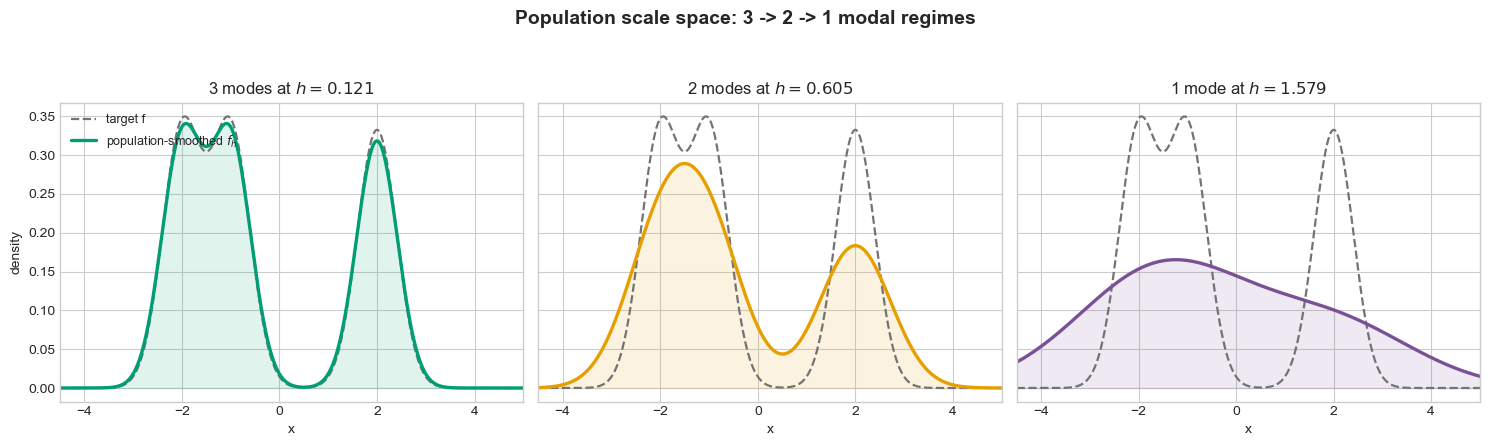

In [31]:
TARGET_DENSITY = mixture_density(
    x=PLOT_X_GRID,
    weights=WEIGHTS,
    means=MEANS,
    sigmas=COMPONENT_SIGMAS,
)
REPRESENTATIVE_INDICES = {}
for mode_count in (3, 2, 1):
    candidates = np.flatnonzero(POPULATION_MODE_COUNTS == mode_count)
    REPRESENTATIVE_INDICES[mode_count] = int(candidates[len(candidates) // 2])

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.5), sharey=True)                                    ### PLOTTING
for axis, mode_count in zip(axes, (3, 2, 1)):
    index = REPRESENTATIVE_INDICES[mode_count]
    h_value = float(H_GRID[index])
    smoothed_density = population_smoothed_density(h_value, PLOT_X_GRID)
    color = MODE_COLORS[mode_count]
    mode_label = "mode" if mode_count == 1 else "modes"

    axis.plot(PLOT_X_GRID, TARGET_DENSITY, color="0.45", linestyle="--", linewidth=1.6, label="target f")  ### PLOTTING
    axis.plot(PLOT_X_GRID, smoothed_density, color=color, linewidth=2.4, label=rf"population-smoothed $f_h$")  ### PLOTTING
    axis.fill_between(PLOT_X_GRID, smoothed_density, color=color, alpha=0.12)                       ### PLOTTING
    axis.set_title(rf"{mode_count} {mode_label} at $h={h_value:.3f}$")
    axis.set_xlabel("x")                                                                            ### PLOTTING
    axis.set_xlim(PLOT_X_GRID[0], PLOT_X_GRID[-1])                                                  ### PLOTTING

axes[0].set_ylabel("density")                                                                       ### PLOTTING
axes[0].legend(loc="upper left", fontsize=9)                                                        ### PLOTTING
fig.suptitle("Population scale space: 3 -> 2 -> 1 modal regimes", fontsize=14, fontweight="bold")   ### PLOTTING
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.93))                                                        ### PLOTTING
plt.show()                                                                                          ### PLOTTING
plt.close(fig)                                                                                      ### PLOTTING


## 2. Scale-by-scale reweighting

The first panel reports the probability weights $v_i$ themselves. The second divides them by the uniform base weights, producing $Nv_i$. The third shows the stronger stationary reweighting $N\pi_i$.


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/three_component_gmm_perron_vs_qhat/002_scale_by_scale_perron_and_doob_reweighting.pdf


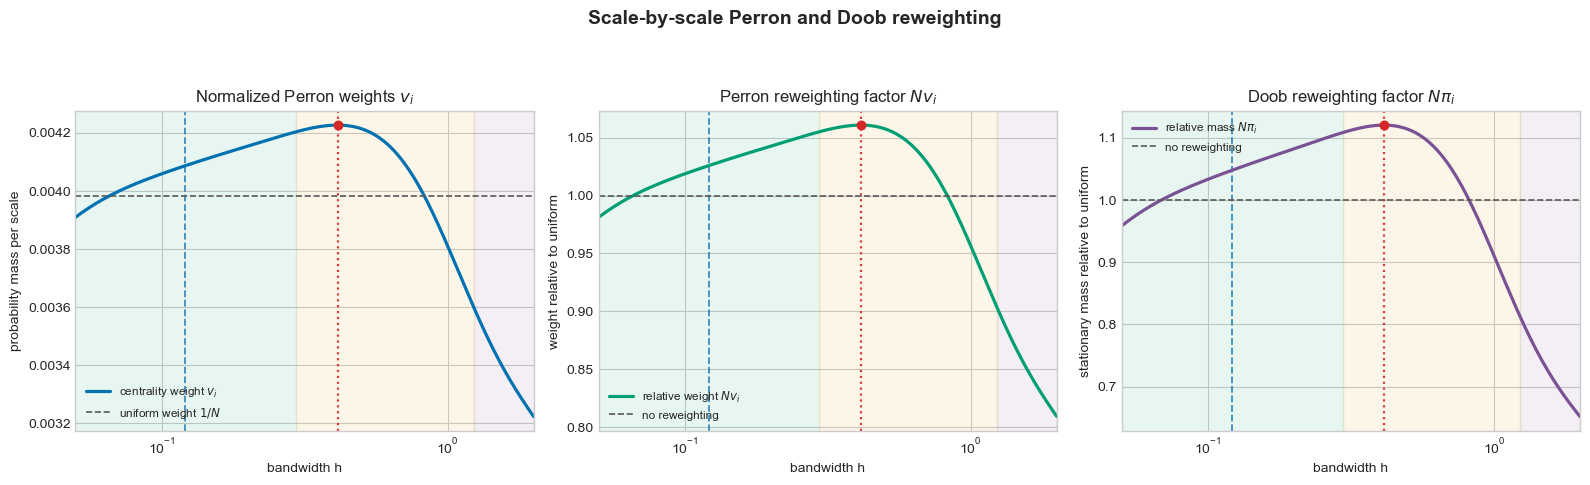

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.9), sharex=True)                                    ### PLOTTING
for axis in axes:
    shade_mode_regimes(axis, REGIME_RECORDS)
    axis.axvline(H_Q, color="tab:blue", linestyle="--", linewidth=1.3, alpha=0.85)                  ### PLOTTING
    axis.axvline(H_PERRON, color="tab:red", linestyle=":", linewidth=1.6, alpha=0.9)                ### PLOTTING
    axis.set_xscale("log")                                                                          ### PLOTTING
    axis.set_xlim(H_MIN, H_MAX)                                                                     ### PLOTTING
    axis.set_xlabel("bandwidth h")                                                                  ### PLOTTING

axes[0].plot(H_GRID, PERRON_WEIGHTS, color="#0072B2", linewidth=2.3, label=r"centrality weight $v_i$")  ### PLOTTING
axes[0].axhline(1.0 / N_BANDWIDTHS, color="0.35", linestyle="--", linewidth=1.2, label=r"uniform weight $1/N$")  ### PLOTTING
axes[0].scatter([H_PERRON], [PERRON_WEIGHTS[PERRON_INDEX]], color="tab:red", s=38, zorder=4)        ### PLOTTING
axes[0].set_ylabel("probability mass per scale")                                                    ### PLOTTING
axes[0].set_title(r"Normalized Perron weights $v_i$")
axes[0].legend(loc="best", fontsize=8.5)                                                            ### PLOTTING

axes[1].plot(H_GRID, RELATIVE_PERRON_WEIGHTS, color="#009E73", linewidth=2.3, label=r"relative weight $Nv_i$")  ### PLOTTING
axes[1].axhline(1.0, color="0.35", linestyle="--", linewidth=1.2, label="no reweighting")           ### PLOTTING
axes[1].scatter([H_PERRON], [RELATIVE_PERRON_WEIGHTS[PERRON_INDEX]], color="tab:red", s=38, zorder=4)  ### PLOTTING
axes[1].set_ylabel("weight relative to uniform")                                                    ### PLOTTING
axes[1].set_title(r"Perron reweighting factor $Nv_i$")
axes[1].legend(loc="best", fontsize=8.5)                                                            ### PLOTTING

axes[2].plot(H_GRID, RELATIVE_DOOB_WEIGHTS, color="#7A5195", linewidth=2.3, label=r"relative mass $N\pi_i$")  ### PLOTTING
axes[2].axhline(1.0, color="0.35", linestyle="--", linewidth=1.2, label="no reweighting")           ### PLOTTING
axes[2].scatter([H_DOOB], [RELATIVE_DOOB_WEIGHTS[DOOB_INDEX]], color="tab:red", s=38, zorder=4)     ### PLOTTING
axes[2].set_ylabel("stationary mass relative to uniform")                                           ### PLOTTING
axes[2].set_title(r"Doob reweighting factor $N\pi_i$")
axes[2].legend(loc="best", fontsize=8.5)                                                            ### PLOTTING

fig.suptitle("Scale-by-scale Perron and Doob reweighting", fontsize=14, fontweight="bold")          ### PLOTTING
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.92))                                                        ### PLOTTING
plt.show()                                                                                          ### PLOTTING
plt.close(fig)                                                                                      ### PLOTTING


## 3. Reweighted mass of the modal regimes

Absolute mass distinguishes a large regime from a highly favored regime. Relative lift divides each regime's Perron or Doob mass by the mass it already had under the uniform grid, separating genuine reweighting from the number of grid points in that regime.


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/three_component_gmm_perron_vs_qhat/003_modal_regime_mass_under_three_scale_measures.pdf


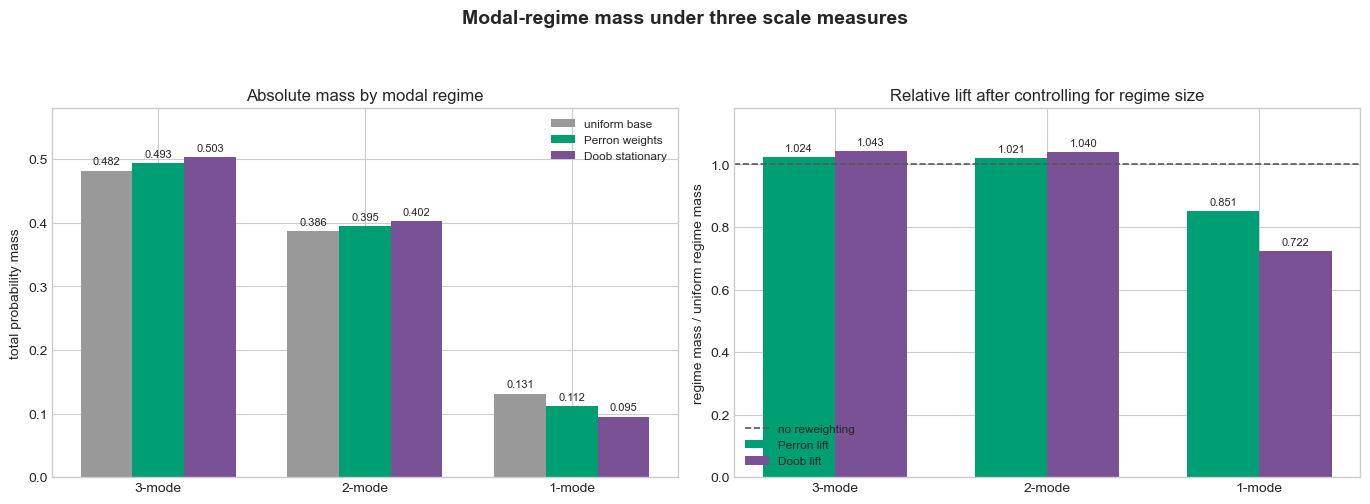

In [33]:
regime_labels = REGIME_WEIGHT_TABLE["regime"].str.replace(" modes", "-mode", regex=False).tolist()
positions = np.arange(len(regime_labels))

fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.1))                                                 ### PLOTTING
mass_axis, lift_axis = axes
bar_width = 0.25
uniform_bars = mass_axis.bar(positions - bar_width, REGIME_WEIGHT_TABLE["uniform_mass"], width=bar_width, color="0.60", label="uniform base")  ### PLOTTING
perron_bars = mass_axis.bar(positions, REGIME_WEIGHT_TABLE["perron_mass"], width=bar_width, color="#009E73", label="Perron weights")  ### PLOTTING
doob_bars = mass_axis.bar(positions + bar_width, REGIME_WEIGHT_TABLE["doob_mass"], width=bar_width, color="#7A5195", label="Doob stationary")  ### PLOTTING
mass_axis.set_xticks(positions, regime_labels)                                                      ### PLOTTING
mass_axis.set_ylabel("total probability mass")                                                      ### PLOTTING
mass_axis.set_ylim(0.0, 0.58)                                                                       ### PLOTTING
mass_axis.set_title("Absolute mass by modal regime")
mass_axis.legend(loc="upper right", fontsize=8.5)                                                   ### PLOTTING
for container in (uniform_bars, perron_bars, doob_bars):                                            ### PLOTTING
    mass_axis.bar_label(container, fmt="%.3f", padding=3, fontsize=8)                               ### PLOTTING

lift_width = 0.34
perron_lift_bars = lift_axis.bar(positions - lift_width / 2.0, REGIME_WEIGHT_TABLE["perron_lift"], width=lift_width, color="#009E73", label="Perron lift")  ### PLOTTING
doob_lift_bars = lift_axis.bar(positions + lift_width / 2.0, REGIME_WEIGHT_TABLE["doob_lift"], width=lift_width, color="#7A5195", label="Doob lift")  ### PLOTTING
lift_axis.axhline(1.0, color="0.35", linestyle="--", linewidth=1.2, label="no reweighting")         ### PLOTTING
lift_axis.set_xticks(positions, regime_labels)                                                      ### PLOTTING
lift_axis.set_ylabel("regime mass / uniform regime mass")                                           ### PLOTTING
lift_axis.set_ylim(0.0, 1.18)                                                                       ### PLOTTING
lift_axis.set_title("Relative lift after controlling for regime size")
lift_axis.legend(loc="lower left", fontsize=8.5)                                                    ### PLOTTING
for container in (perron_lift_bars, doob_lift_bars):                                                ### PLOTTING
    lift_axis.bar_label(container, fmt="%.3f", padding=3, fontsize=8)                               ### PLOTTING

fig.suptitle("Modal-regime mass under three scale measures", fontsize=14, fontweight="bold")        ### PLOTTING
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.92))                                                        ### PLOTTING
plt.show()                                                                                          ### PLOTTING
plt.close(fig)                                                                                      ### PLOTTING


## 4. Local stability versus global reweighting

$\widehat Q$ is a pointwise local criterion. The similarity row mass is a one-step global summary, while Perron and Doob weights recursively account for the weights of neighboring scales. Their peaks need not coincide at finite $N$ and $\lambda$.


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/three_component_gmm_perron_vs_qhat/004_local_stability_versus_global_similarity_reweighting.pdf


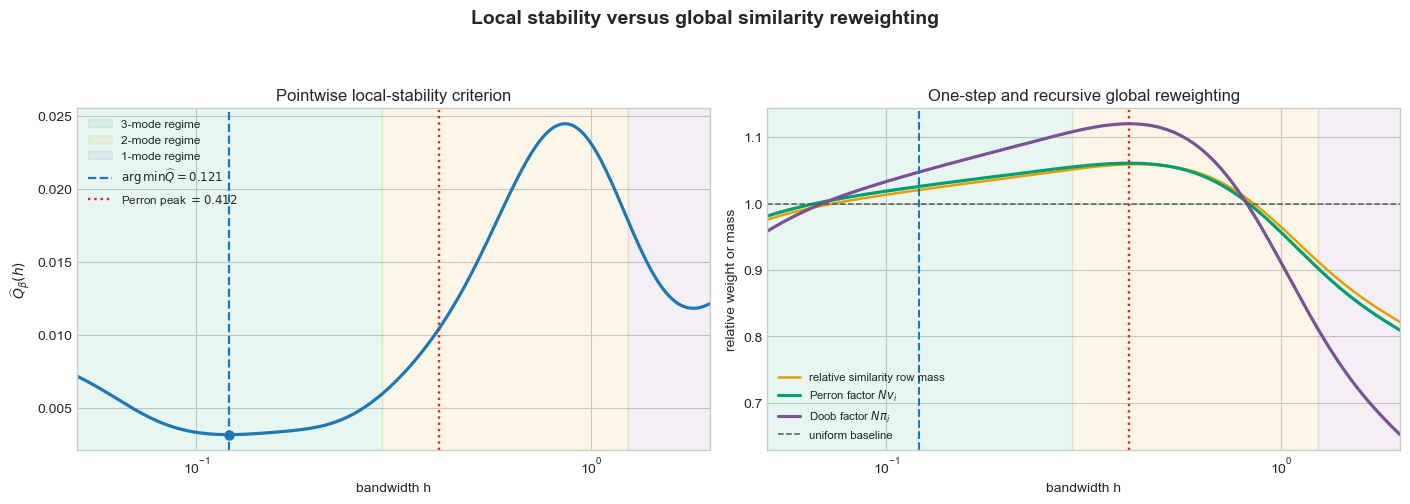

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14.2, 5.1), sharex=True)                                    ### PLOTTING
q_axis, global_axis = axes
shade_mode_regimes(q_axis, REGIME_RECORDS, with_labels=True)
shade_mode_regimes(global_axis, REGIME_RECORDS)

q_axis.plot(H_GRID, Q_HAT, color="tab:blue", linewidth=2.3)                                         ### PLOTTING
q_axis.scatter([H_Q], [Q_HAT[Q_INDEX]], color="tab:blue", s=42, zorder=4)                           ### PLOTTING
q_axis.axvline(H_Q, color="tab:blue", linestyle="--", linewidth=1.6, label=rf"$\arg\min \widehat Q={H_Q:.3f}$")  ### PLOTTING
q_axis.axvline(H_PERRON, color="tab:red", linestyle=":", linewidth=1.7, label=rf"Perron peak $={H_PERRON:.3f}$")  ### PLOTTING
q_axis.set_ylabel(r"$\widehat Q_\beta(h)$")                                                         ### PLOTTING
q_axis.set_title("Pointwise local-stability criterion")
q_axis.legend(loc="best", fontsize=8.5)                                                             ### PLOTTING

global_axis.plot(H_GRID, ROW_MASS_RELATIVE, color="#E69F00", linewidth=1.8, label="relative similarity row mass")  ### PLOTTING
global_axis.plot(H_GRID, RELATIVE_PERRON_WEIGHTS, color="#009E73", linewidth=2.3, label=r"Perron factor $Nv_i$")  ### PLOTTING
global_axis.plot(H_GRID, RELATIVE_DOOB_WEIGHTS, color="#7A5195", linewidth=2.3, label=r"Doob factor $N\pi_i$")  ### PLOTTING
global_axis.axhline(1.0, color="0.35", linestyle="--", linewidth=1.1, label="uniform baseline")     ### PLOTTING
global_axis.axvline(H_Q, color="tab:blue", linestyle="--", linewidth=1.5)                           ### PLOTTING
global_axis.axvline(H_PERRON, color="tab:red", linestyle=":", linewidth=1.7)                        ### PLOTTING
global_axis.set_ylabel("relative weight or mass")                                                   ### PLOTTING
global_axis.set_title("One-step and recursive global reweighting")
global_axis.legend(loc="best", fontsize=8.2)                                                        ### PLOTTING

for axis in axes:                                                                                   ### PLOTTING
    axis.set_xscale("log")                                                                          ### PLOTTING
    axis.set_xlim(H_MIN, H_MAX)                                                                     ### PLOTTING
    axis.set_xlabel("bandwidth h")                                                                  ### PLOTTING

fig.suptitle("Local stability versus global similarity reweighting", fontsize=14, fontweight="bold")  ### PLOTTING
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.92))                                                        ### PLOTTING
plt.show()                                                                                          ### PLOTTING
plt.close(fig)                                                                                      ### PLOTTING


## 5. Similarity geometry and selected KDEs

The heat map shows the complete graph from which the weights arise. The right panel compares the local $\widehat Q$ minimum and the Perron/Doob maximum with the Sheather--Jones solve-the-equation plug-in bandwidth and ordinary least-squares cross-validation. The two classical selectors are comparison estimators, not summaries of the Perron scale distribution.


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/three_component_gmm_perron_vs_qhat/005_similarity_geometry_and_selected_kdes.pdf


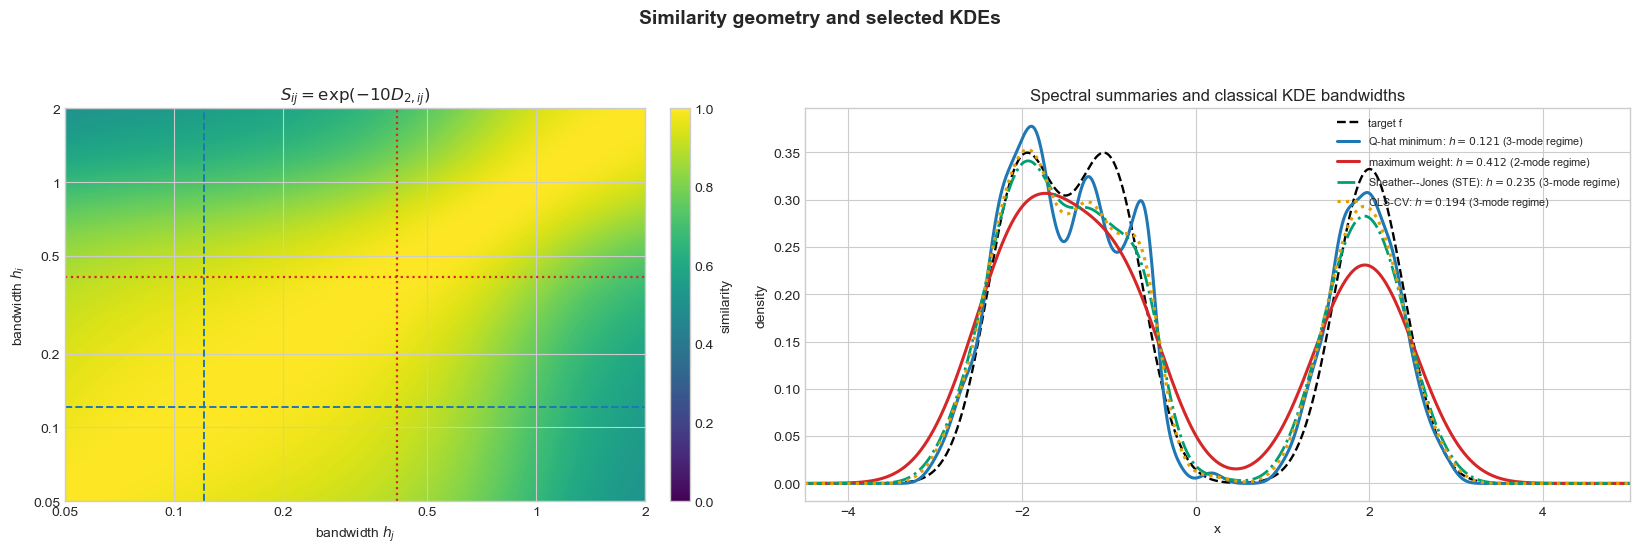

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.6), gridspec_kw={"width_ratios": [1.0, 1.3]})       ### PLOTTING
matrix_axis, density_axis = axes
log_h_min = float(np.log10(H_MIN))
log_h_max = float(np.log10(H_MAX))
image = matrix_axis.imshow(                                                                         ### PLOTTING
    SIMILARITY,                                                                                     ### PLOTTING
    origin="lower",                                                                                 ### PLOTTING
    aspect="auto",                                                                                  ### PLOTTING
    extent=(log_h_min, log_h_max, log_h_min, log_h_max),                                            ### PLOTTING
    cmap="viridis",                                                                                 ### PLOTTING
    vmin=0.0,                                                                                       ### PLOTTING
    vmax=1.0,                                                                                       ### PLOTTING
)                                                                                                   ### PLOTTING
tick_bandwidths = np.array([0.05, 0.1, 0.2, 0.5, 1.0, 2.0])
tick_positions = np.log10(tick_bandwidths)
matrix_axis.set_xticks(tick_positions, [f"{h:g}" for h in tick_bandwidths])                         ### PLOTTING
matrix_axis.set_yticks(tick_positions, [f"{h:g}" for h in tick_bandwidths])                         ### PLOTTING
matrix_axis.axvline(np.log10(H_Q), color="tab:blue", linestyle="--", linewidth=1.4)                 ### PLOTTING
matrix_axis.axhline(np.log10(H_Q), color="tab:blue", linestyle="--", linewidth=1.4)                 ### PLOTTING
matrix_axis.axvline(np.log10(H_PERRON), color="tab:red", linestyle=":", linewidth=1.6)              ### PLOTTING
matrix_axis.axhline(np.log10(H_PERRON), color="tab:red", linestyle=":", linewidth=1.6)              ### PLOTTING
matrix_axis.set_xlabel(r"bandwidth $h_j$")                                                          ### PLOTTING
matrix_axis.set_ylabel(r"bandwidth $h_i$")                                                          ### PLOTTING
matrix_axis.set_title(rf"$S_{{ij}}=\exp(-{LAMBDA:g}D_{{2,ij}})$")
fig.colorbar(image, ax=matrix_axis, fraction=0.046, pad=0.04, label="similarity")                   ### PLOTTING

selected_kdes = gaussian_kde_values(
    samples=SAMPLES,
    h_grid=np.array([H_Q, H_PERRON, H_SHEATHER_JONES, H_OLS_CV]),
    x_grid=PLOT_X_GRID,
)
density_axis.plot(PLOT_X_GRID, TARGET_DENSITY, color="black", linestyle="--", linewidth=1.7, label="target f")  ### PLOTTING
density_axis.plot(PLOT_X_GRID, selected_kdes[0], color="tab:blue", linewidth=2.2, label=rf"Q-hat minimum: $h={H_Q:.3f}$ ({POPULATION_MODE_COUNTS[Q_INDEX]}-mode regime)")  ### PLOTTING
density_axis.plot(PLOT_X_GRID, selected_kdes[1], color="tab:red", linewidth=2.2, label=rf"maximum weight: $h={H_PERRON:.3f}$ ({POPULATION_MODE_COUNTS[PERRON_INDEX]}-mode regime)")  ### PLOTTING
density_axis.plot(PLOT_X_GRID, selected_kdes[2], color="#009E73", linestyle="-.", linewidth=2.0, label=rf"Sheather--Jones (STE): $h={H_SHEATHER_JONES:.3f}$ ({population_mode_count(H_SHEATHER_JONES)}-mode regime)")  ### PLOTTING
density_axis.plot(PLOT_X_GRID, selected_kdes[3], color="#E69F00", linestyle=":", linewidth=2.3, label=rf"OLS-CV: $h={H_OLS_CV:.3f}$ ({POPULATION_MODE_COUNTS[OLS_CV_INDEX]}-mode regime)")  ### PLOTTING
density_axis.set_xlabel("x")                                                                        ### PLOTTING
density_axis.set_ylabel("density")                                                                  ### PLOTTING
density_axis.set_title("Spectral summaries and classical KDE bandwidths")
density_axis.set_xlim(PLOT_X_GRID[0], PLOT_X_GRID[-1])                                              ### PLOTTING
density_axis.legend(loc="upper right", fontsize=7.8)                                                ### PLOTTING

fig.suptitle("Similarity geometry and selected KDEs", fontsize=14, fontweight="bold")               ### PLOTTING
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.93))                                                        ### PLOTTING
plt.show()                                                                                          ### PLOTTING
plt.close(fig)                                                                                      ### PLOTTING


## 6. How the reweighting changes with $\lambda$

The divergence matrix stays fixed while $\lambda$ varies. The panels show the location of the largest weight, the redistribution of total Perron mass between regimes, and the effective fraction of supported scales.


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/three_component_gmm_perron_vs_qhat/006_reweighting_across_similarity_scales.pdf


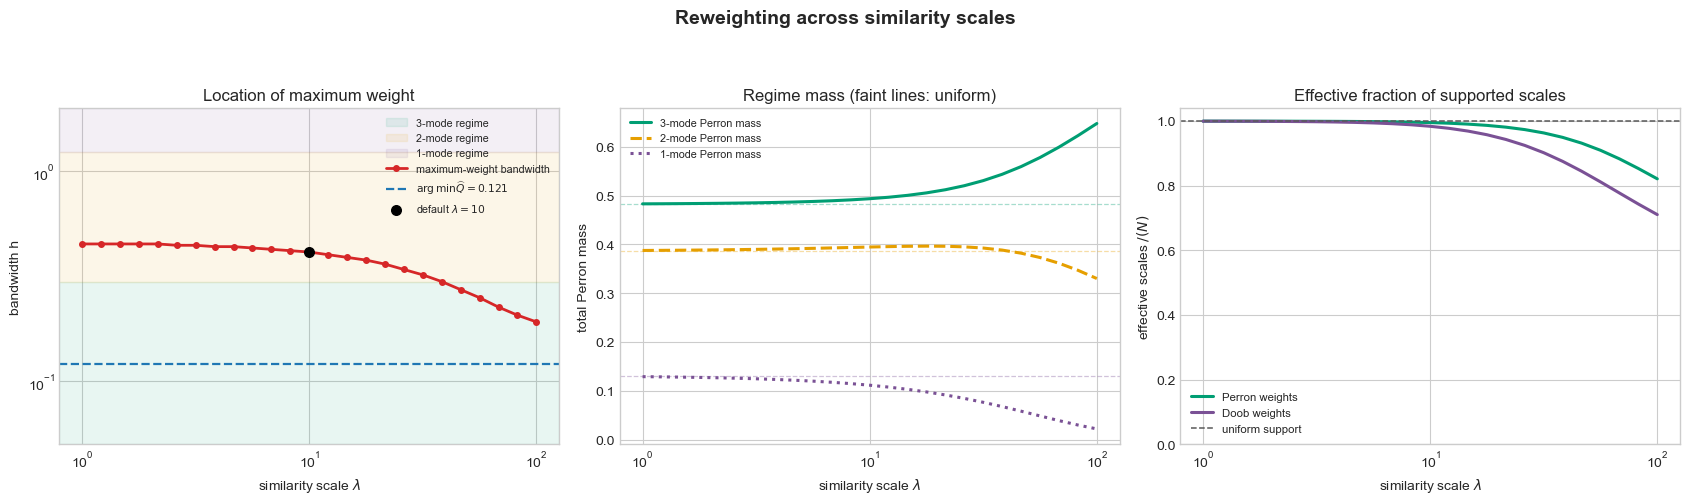

,lambda,selected_h,population_modes,perron_effective_fraction,doob_effective_fraction,perron_mass_3,perron_mass_2,perron_mass_1
0,1.000000,0.450607,2,0.999951,0.999805,0.482964,0.387606,0.129430
1,1.211528,0.450607,2,0.999928,0.999714,0.483161,0.387840,0.129000
2,1.467799,0.450607,2,0.999894,0.999583,0.483402,0.388118,0.128480
3,1.778279,0.450607,2,0.999845,0.999393,0.483700,0.388448,0.127852
4,2.154435,0.450607,2,0.999774,0.999116,0.484068,0.388838,0.127094
5,2.610157,0.444007,2,0.999670,0.998715,0.484525,0.389296,0.126179
6,3.162278,0.444007,2,0.999518,0.998137,0.485094,0.389830,0.125076
7,3.831187,0.437503,2,0.999297,0.997306,0.485807,0.390445,0.123748
8,4.641589,0.437503,2,0.998978,0.996118,0.486702,0.391146,0.122152
9,5.623413,0.431095,2,0.998515,0.994427,0.487834,0.391931,0.120235


In [10]:
LAMBDA_GRID = np.geomspace(1.0, 100.0, 25)
lambda_rows = []
for lambda_value in LAMBDA_GRID:
    current_similarity = np.exp(-lambda_value * DIVERGENCE)
    np.fill_diagonal(current_similarity, 1.0)
    current_v = perron_vector(current_similarity)
    current_pi = current_v**2
    current_pi /= current_pi.sum()
    current_index = int(np.argmax(current_v))
    row = {
        "lambda": float(lambda_value),
        "selected_h": float(H_GRID[current_index]),
        "population_modes": int(POPULATION_MODE_COUNTS[current_index]),
        "perron_effective_fraction": float(1.0 / np.sum(current_v**2) / N_BANDWIDTHS),
        "doob_effective_fraction": float(1.0 / np.sum(current_pi**2) / N_BANDWIDTHS),
    }
    for record in REGIME_RECORDS:
        mode_count = int(record["mode_count"])
        selection = slice(int(record["start"]), int(record["end"]))
        row[f"perron_mass_{mode_count}"] = float(current_v[selection].sum())
    lambda_rows.append(row)
LAMBDA_RESULTS = pd.DataFrame(lambda_rows)

fig, axes = plt.subplots(1, 3, figsize=(17.0, 5.1))                                                 ### PLOTTING
selection_axis, mass_axis, support_axis = axes

for record in REGIME_RECORDS:
    mode_count = int(record["mode_count"])
    selection_axis.axhspan(float(record["left"]), float(record["right"]), color=MODE_COLORS[mode_count], alpha=0.09, label=f"{mode_count}-mode regime")  ### PLOTTING
selection_axis.plot(LAMBDA_RESULTS["lambda"], LAMBDA_RESULTS["selected_h"], color="tab:red", marker="o", markersize=4.0, linewidth=2.0, label="maximum-weight bandwidth")  ### PLOTTING
selection_axis.axhline(H_Q, color="tab:blue", linestyle="--", linewidth=1.6, label=rf"$\arg\min \widehat Q={H_Q:.3f}$")  ### PLOTTING
selection_axis.scatter([LAMBDA], [H_PERRON], color="black", s=48, zorder=5, label=rf"default $\lambda={LAMBDA:g}$")  ### PLOTTING
selection_axis.set_xscale("log")                                                                    ### PLOTTING
selection_axis.set_yscale("log")                                                                    ### PLOTTING
selection_axis.set_ylim(H_MIN, H_MAX)                                                               ### PLOTTING
selection_axis.set_xlabel(r"similarity scale $\lambda$")                                            ### PLOTTING
selection_axis.set_ylabel("bandwidth h")                                                            ### PLOTTING
selection_axis.set_title("Location of maximum weight")
selection_axis.legend(loc="best", fontsize=7.7)                                                     ### PLOTTING

for record, linestyle in zip(REGIME_RECORDS, ("-", "--", ":")):
    mode_count = int(record["mode_count"])
    uniform_mass = float(REGIME_WEIGHT_TABLE.loc[REGIME_WEIGHT_TABLE["regime"] == f"{mode_count} modes", "uniform_mass"].iloc[0])
    mass_axis.plot(LAMBDA_RESULTS["lambda"], LAMBDA_RESULTS[f"perron_mass_{mode_count}"], color=MODE_COLORS[mode_count], linestyle=linestyle, linewidth=2.2, label=f"{mode_count}-mode Perron mass")  ### PLOTTING
    mass_axis.axhline(uniform_mass, color=MODE_COLORS[mode_count], linestyle="--", linewidth=0.9, alpha=0.35)  ### PLOTTING
mass_axis.set_xscale("log")                                                                         ### PLOTTING
mass_axis.set_xlabel(r"similarity scale $\lambda$")                                                 ### PLOTTING
mass_axis.set_ylabel("total Perron mass")                                                           ### PLOTTING
mass_axis.set_title("Regime mass (faint lines: uniform)")
mass_axis.legend(loc="best", fontsize=7.8)                                                          ### PLOTTING

support_axis.plot(LAMBDA_RESULTS["lambda"], LAMBDA_RESULTS["perron_effective_fraction"], color="#009E73", linewidth=2.2, label="Perron weights")  ### PLOTTING
support_axis.plot(LAMBDA_RESULTS["lambda"], LAMBDA_RESULTS["doob_effective_fraction"], color="#7A5195", linewidth=2.2, label="Doob weights")  ### PLOTTING
support_axis.axhline(1.0, color="0.35", linestyle="--", linewidth=1.1, label="uniform support")     ### PLOTTING
support_axis.set_xscale("log")                                                                      ### PLOTTING
support_axis.set_ylim(0.0, 1.04)                                                                    ### PLOTTING
support_axis.set_xlabel(r"similarity scale $\lambda$")                                              ### PLOTTING
support_axis.set_ylabel(r"effective scales $/(N)$")                                                 ### PLOTTING
support_axis.set_title("Effective fraction of supported scales")
support_axis.legend(loc="best", fontsize=8.2)                                                       ### PLOTTING

fig.suptitle("Reweighting across similarity scales", fontsize=14, fontweight="bold")                ### PLOTTING
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.92))                                                        ### PLOTTING
plt.show()                                                                                          ### PLOTTING
plt.close(fig)                                                                                      ### PLOTTING

LAMBDA_RESULTS.round(6)


## Interpretation

For the default finite experiment, the largest Perron and Doob weight lies in the 2-mode regime, whereas the pointwise $\widehat Q$ minimum lies in the 3-mode regime. Sheather--Jones (STE) and OLS-CV provide classical, data-driven reference bandwidths in the density panel; they do not alter the Perron or Doob weights. The regime-level table is the more important reweighting result: it shows separately how much mass a regime receives and how strongly that mass differs from its uniform-grid baseline.

The experiment should therefore be described as a reweighting of a base measure on scales. The maximum-weight bandwidth is one possible summary of that measure, not the measure itself.
